## Initiation - directory and file selection and loading

In [1]:
%%script false --no-raise-error

# mahdi colab
%pip install pydicom SimpleITK nibabel
from google.colab import drive  # Imports the drive module from google.colab library.

drive.mount('/content/drive')  # Mounts the Google Drive to the specified mount point '/content/drive'.
hgucegxi_dir = r"/content/drive/MyDrive/VUB/Hospital Project/HGUCEGXI"  # Sets the variable `hgucegxi_dir` with the path to a specific directory within Google Drive.
nifti_dir = r"/content/drive/MyDrive/VUB/Hospital Project/HGUCEGXI.nii"

Couldn't find program: 'false'


In [2]:
# %%script false --no-raise-error

# hossein local
hgucegxi_dir = r"Dataset\DICOMs\HGUCEGXI"
nifti_dir = r'Dataset\NIFTIs\HGUCEGXI.nii'

In [3]:
import os  # Provides a way of using operating system dependent functionality like reading or writing to the filesystem.
import \
    pydicom  # A Python library for working with DICOM files. It allows for easy manipulation of DICOM images and metadata.
import \
    SimpleITK as sitk  # A library for health imaging. It simplifies complex image processing tasks, such as image filtering, segmentation, and registration.
import \
    cv2  # OpenCV library, which is used for computer vision tasks including reading, writing images, and image transformation operations.
import \
    numpy as np  # Fundamental package for scientific computing with Python. It provides support for arrays, matrices, and high-level mathematical functions.
import \
    matplotlib.pyplot as plt  # A plotting library for creating static, interactive, and animated visualizations in Python.
import \
    nibabel as nib  # Library to access a variety of neuroimaging data formats, particularly useful for working with NIfTI and ANALYZE data.

In [4]:
# Uses the `os.listdir` function to retrieve a list of all files (and directories) contained in the `hgucegxi_dir` directory.
files = os.listdir(hgucegxi_dir)

# Slices the list `files` to retrieve the first five elements, which are the names of the first five files (or directories) in the specified directory.
files[:5]

['I1000000', 'I1000001', 'I1010000', 'I1020000', 'I1030000']

In [5]:
from utilities import convert_to_nifti

# Calls the `convert_to_nifti` function with the source directory of DICOM files and the target path for the NIfTI file.
convert_to_nifti(hgucegxi_dir, nifti_dir)

# Reads a NIfTI image file located at the specified path using SimpleITK's ReadImage function.
# The file path is given as a raw string (noted by the 'r' prefix) to avoid the need for escaping backslashes.
# The resulting image is stored in the variable 'sitk_image'.
sitk_image = sitk.ReadImage(nifti_dir)

## visualization to insure correct loading of files

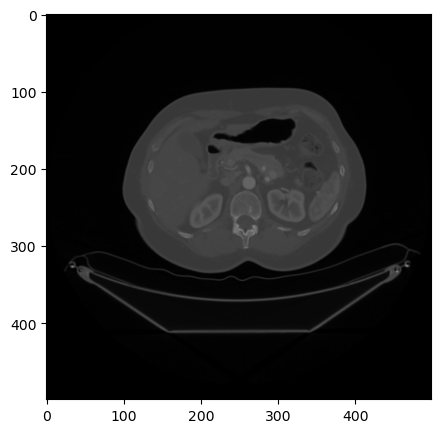

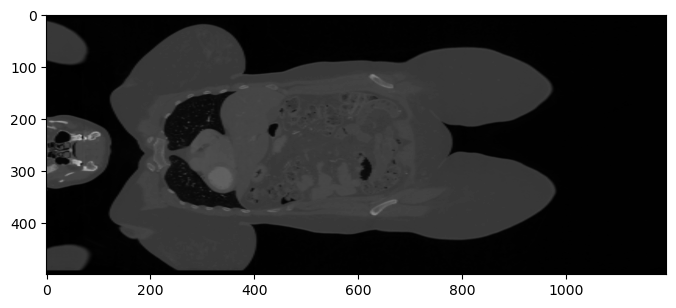

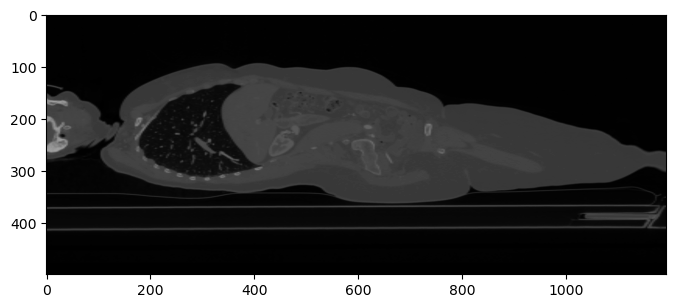

In [6]:
# Define a function to get orthogonal slices from a 3D image at specified indices.
def get_slices(image_3d, x, y, z):
    # Calculate the new spacing to maintain aspect ratio after resizing.
    # It multiplies the physical spacing with the shape of the image and converts to integer.
    spacing = (np.array(sitk_image.GetSpacing()[::-1]) * image_3d.shape[:3]).astype(int)

    # Extract and resize the axial slice at index x.
    x_img = cv2.resize(image_3d[x, :, :].astype(float), spacing[:0:-1])
    # Extract, resize, and rotate the sagittal slice at index y for proper orientation.
    y_img = cv2.rotate(cv2.resize(image_3d[:, y, :].astype(float), spacing[::-2]), cv2.ROTATE_90_CLOCKWISE)
    # Extract, resize, and rotate the coronal slice at index z for proper orientation.
    z_img = cv2.rotate(cv2.resize(image_3d[:, :, z].astype(float), spacing[:2][::-1]), cv2.ROTATE_90_CLOCKWISE)

    # Return the processed slices.
    return x_img, y_img, z_img


def show_slides(slides):
    # Visualize the axial slice.
    plt.figure(figsize=(8, 5))
    plt.imshow(slides[0], cmap='gray', vmin=-1024, vmax=3071)
    plt.show()

    # Visualize the sagittal slice.
    plt.figure(figsize=(8, 5))
    plt.imshow(slides[1], cmap='gray', vmin=-1024, vmax=3071)
    plt.show()

    # Visualize the coronal slice.
    plt.figure(figsize=(8, 8))
    plt.imshow(slides[2], cmap='gray', vmin=-1024, vmax=3071)
    plt.show()


# Convert the SimpleITK image to a NumPy array and get slices from it.
temp = get_slices(sitk.GetArrayFromImage(sitk_image), 250, 180, 215)
# Visualize the axial slice.
show_slides(temp)

# Seed Selection (visually)

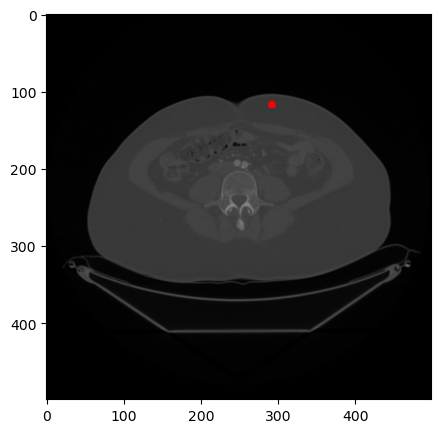

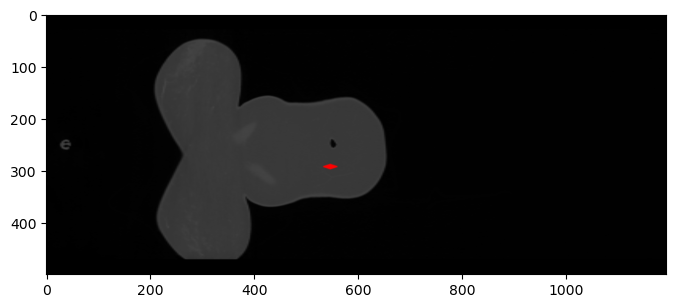

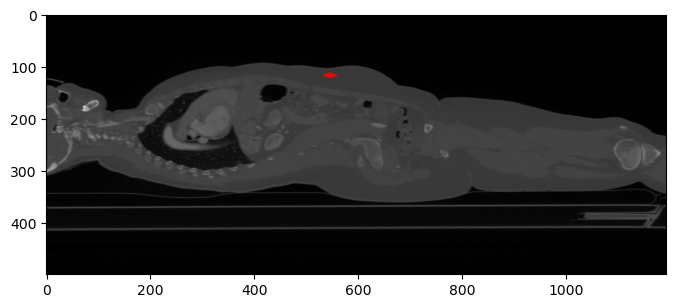

In [7]:
# Set a seed point for visualization
seed = (215, 120, 300)

# Convert the SimpleITK image to a NumPy array
temp = sitk.GetArrayFromImage(sitk_image)

# turn grayscale to rgb
temp = np.stack([temp, temp, temp], axis=-1)
temp = (temp - temp.min()) / (temp.max() - temp.min())

# place a dot at the seed location on the 3d image by going through each slides
for i in range(5):
    temp[seed[0] - i] = cv2.circle(temp[seed[0] - i], (seed[2], seed[1]), 5 - i, (1, 0, 0), -1)
    temp[seed[0] + i] = cv2.circle(temp[seed[0] + i], (seed[2], seed[1]), 5 - i, (1, 0, 0), -1)

temp = get_slices(temp, seed[0], seed[1], seed[2])
show_slides(temp)

## segment fat by using region growing
first narrow range of acceptable intensity change is considered, and then dilated. creating a "fat + area around fat" mask
then another region growing is done with larger range, segmenting the fat and organs.
finally, the intersection of the two masks is considered as the fat mask.

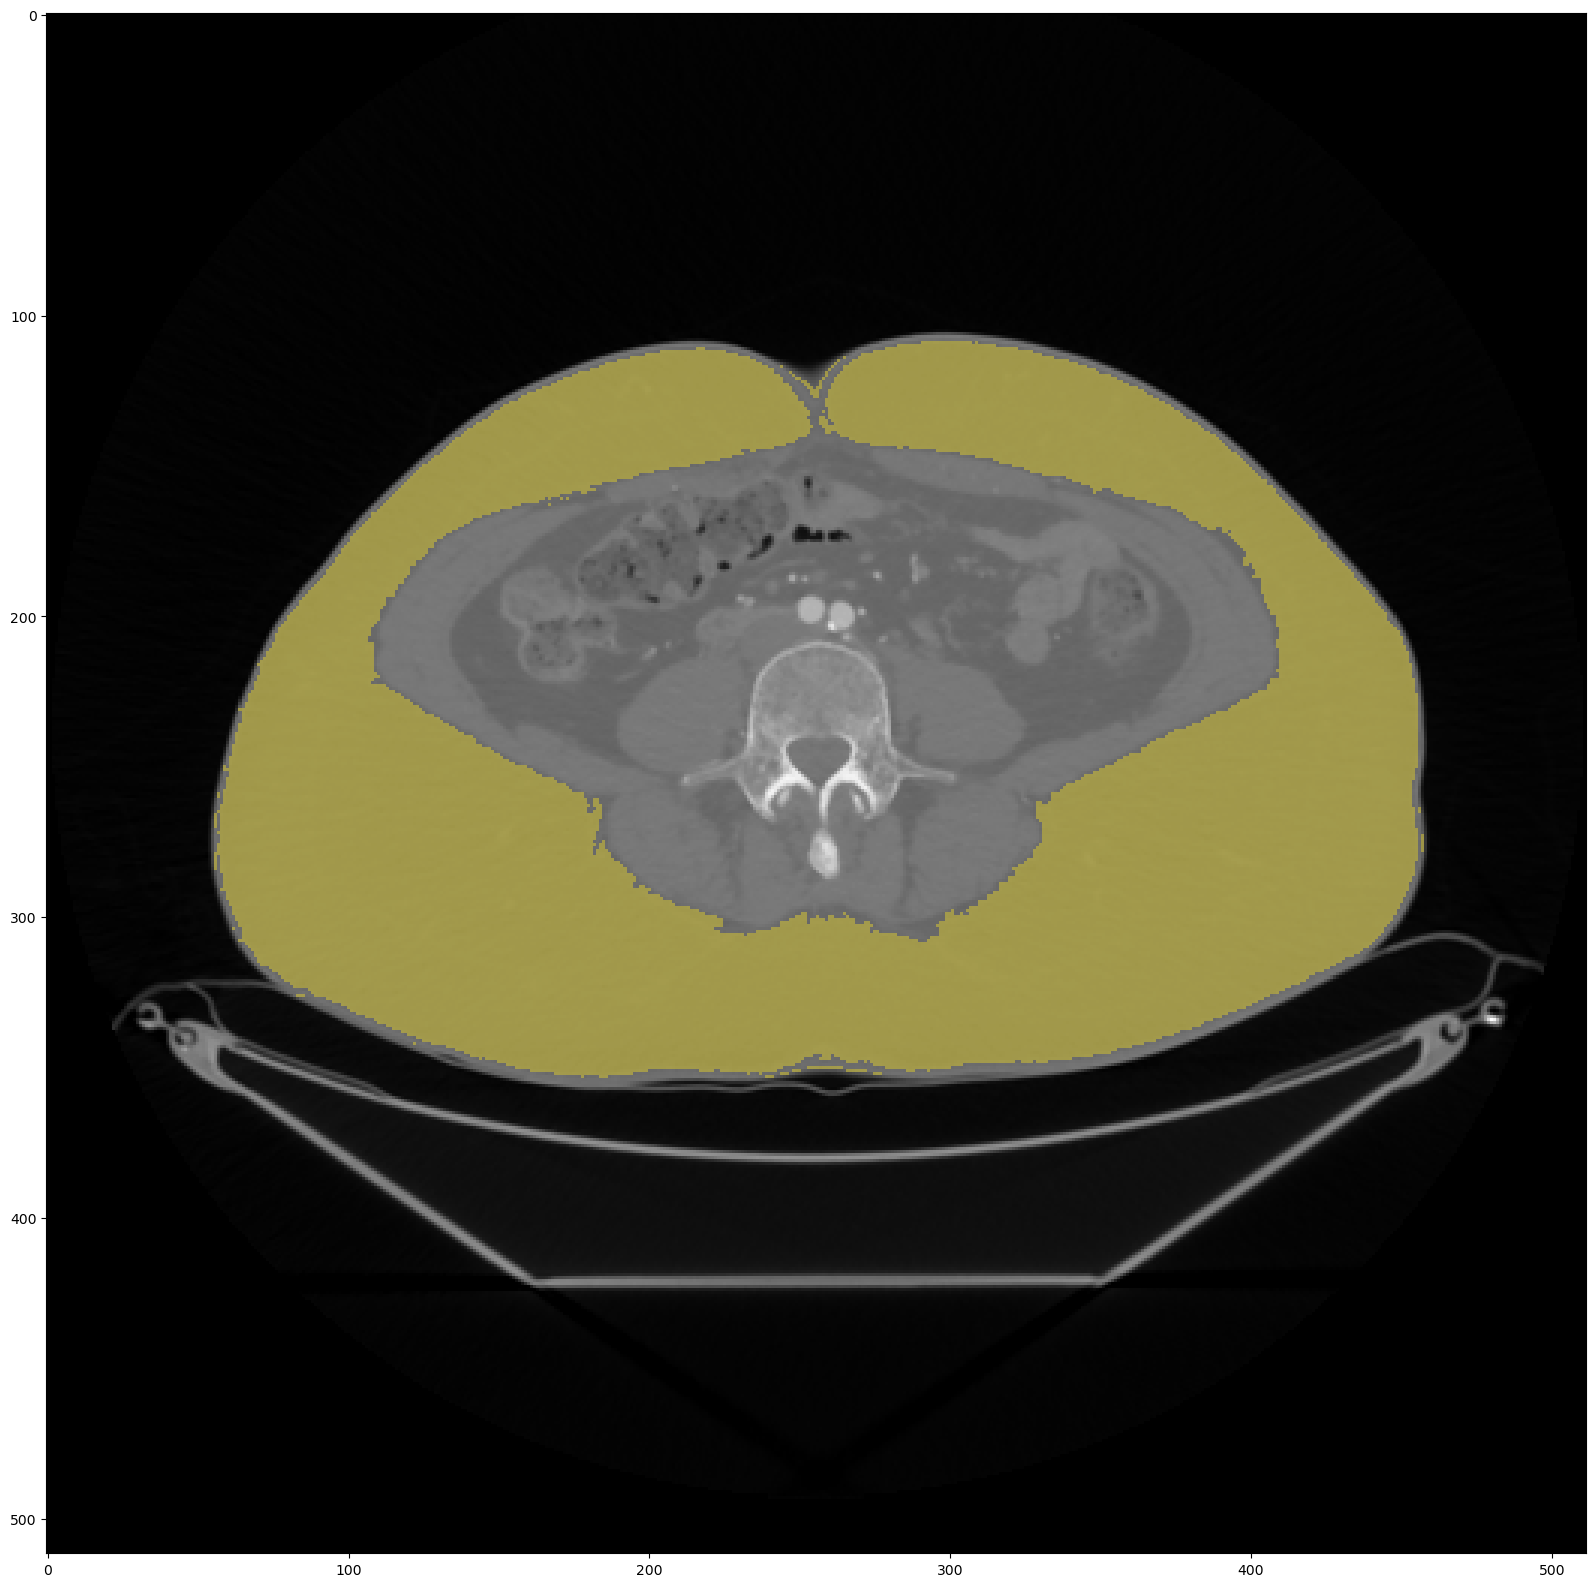

In [176]:
# Define a function to perform region growing segmentation on a SimpleITK image.
def get_region_grown(sitk_image, seed, r, dilation_steps=0):
    # Calculate the average intensity value of the voxel at the seed point and its immediate neighbors.
    # This considers the voxel itself and its neighbors in a 2x2x2 region.
    seed_value = np.mean([
        sitk.GetArrayFromImage(sitk_image)[seed[0] + i[0], seed[1] + i[1], seed[2] + i[2]]
        for i in [[0, 0, 0], [0, 0, 1], [0, 1, 0], [0, 1, 1], [1, 0, 0], [1, 0, 1], [1, 1, 0], [1, 1, 1]]
    ])

    # Perform the region growing segmentation based on the calculated average intensity value as the seed point.
    # `lower` and `upper` bounds for the segmentation are determined by subtracting and adding `r` to the seed value.
    seg_con = sitk.ConnectedThreshold(sitk_image, seedList=[seed], lower=seed_value - r, upper=seed_value + r)

    # Convert the resulting segmentation image back to a NumPy array.
    temp = sitk.GetArrayFromImage(seg_con)

    # The following lines, would apply morphological dilation to the segmented region.
    if dilation_steps != 0:
        temp = cv2.dilate(temp.astype(np.uint8), np.array([[0, 1, 0], [1, 1, 1], [0, 1, 0]]).astype(np.uint8),
                          iterations=dilation_steps)

    return temp

def fill_small_holes(mask, max_size):
    # Find all connected components in the mask.
    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(1-mask.astype(np.uint8))

    # Iterate over the connected components.
    for i in range(1, num_labels):
        # If the area of the connected component is less than the specified maximum size, fill it.
        if stats[i, cv2.CC_STAT_AREA] < max_size:
            mask[labels == i] = 1

    return mask


def segment_fat(sitk_image, seed):
    fat_and_around = get_region_grown(sitk_image, seed, 15, 3)
    fat_and_organs = get_region_grown(sitk_image, seed, 45)
    fat = fat_and_organs * fat_and_around
    
    fat = [fill_small_holes(s, 100) for s in fat]
    fat = np.array(fat)
    
    return fat


sitk_image = sitk.ReadImage(nifti_dir)
plt.figure(figsize=(20, 20))
plt.imshow(sitk.GetArrayFromImage(sitk_image)[seed[0]], cmap='gray')
fat_seg = segment_fat(sitk_image, seed)
plt.imshow(fat_seg[seed[0]], alpha=fat_seg[seed[0]] * 0.4)

## compare the histogram of the image and the segmented fat
it seems the range of histogram for fat is exactly cut out of the histogram of the image 

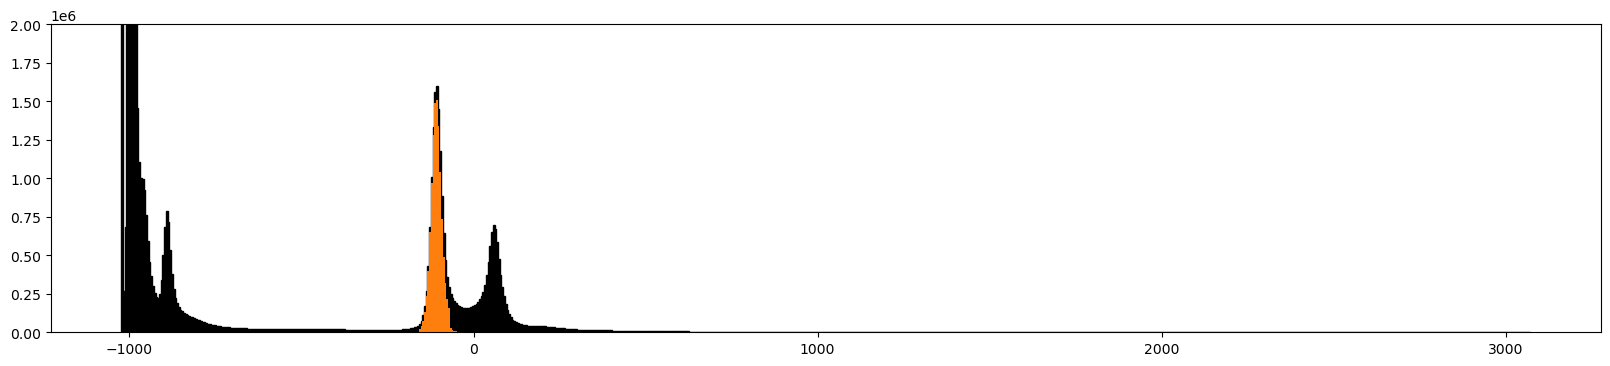

(-175.0, -50.0)

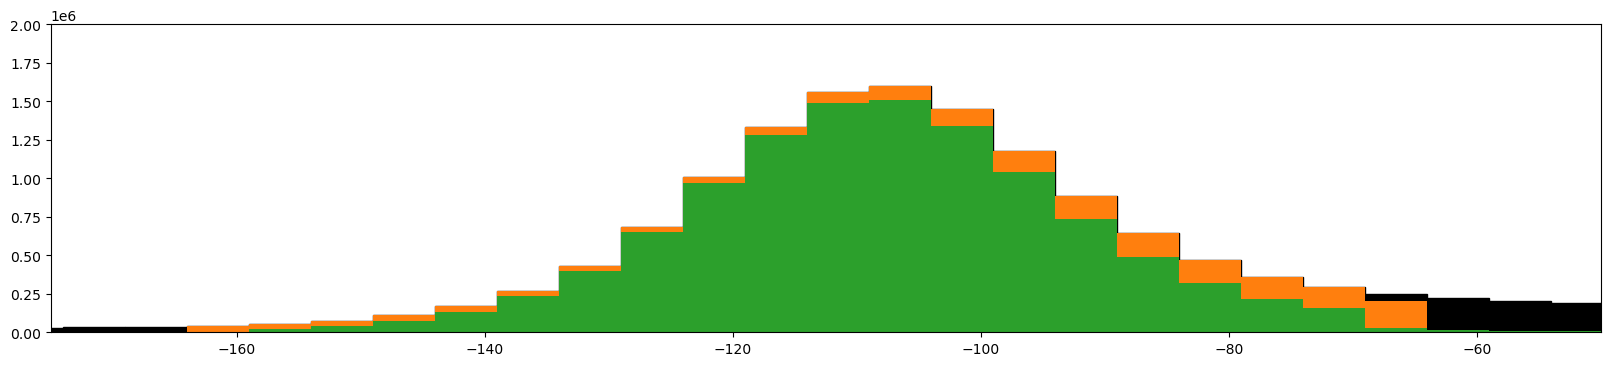

In [177]:
bin_size = 5
plt.figure(figsize=(20, 4))
temp = sitk.GetArrayFromImage(sitk_image)
plt.hist(temp.ravel(), bins=(1024 + 3071) // bin_size, range=(-1024, 3071), fc='k', ec='k')
temp = (temp + 100000) * fat_seg - 100000
plt.hist(temp.ravel(), bins=(1024 + 3071) // bin_size, range=(-1024, 3071))
plt.ylim(0, 2e6)
plt.show()

a_b_range = [-165, -65]
plt.figure(figsize=(20, 4))
temp = sitk.GetArrayFromImage(sitk_image)
plt.hist(temp.ravel(), bins=(1024 + 3071) // bin_size, range=(-1024, 3071), fc='k', ec='k')
temp2 = (temp > a_b_range[0]) & (temp < a_b_range[1])
temp = (temp + 100000) * temp2 - 100000
plt.hist(temp.ravel(), bins=(1024 + 3071) // bin_size, range=(-1024, 3071))
temp = sitk.GetArrayFromImage(sitk_image)
temp = (temp + 100000) * fat_seg - 100000
plt.hist(temp.ravel(), bins=(1024 + 3071) // bin_size, range=(-1024, 3071))
plt.ylim(0, 2e6)
plt.xlim(-175, -50)

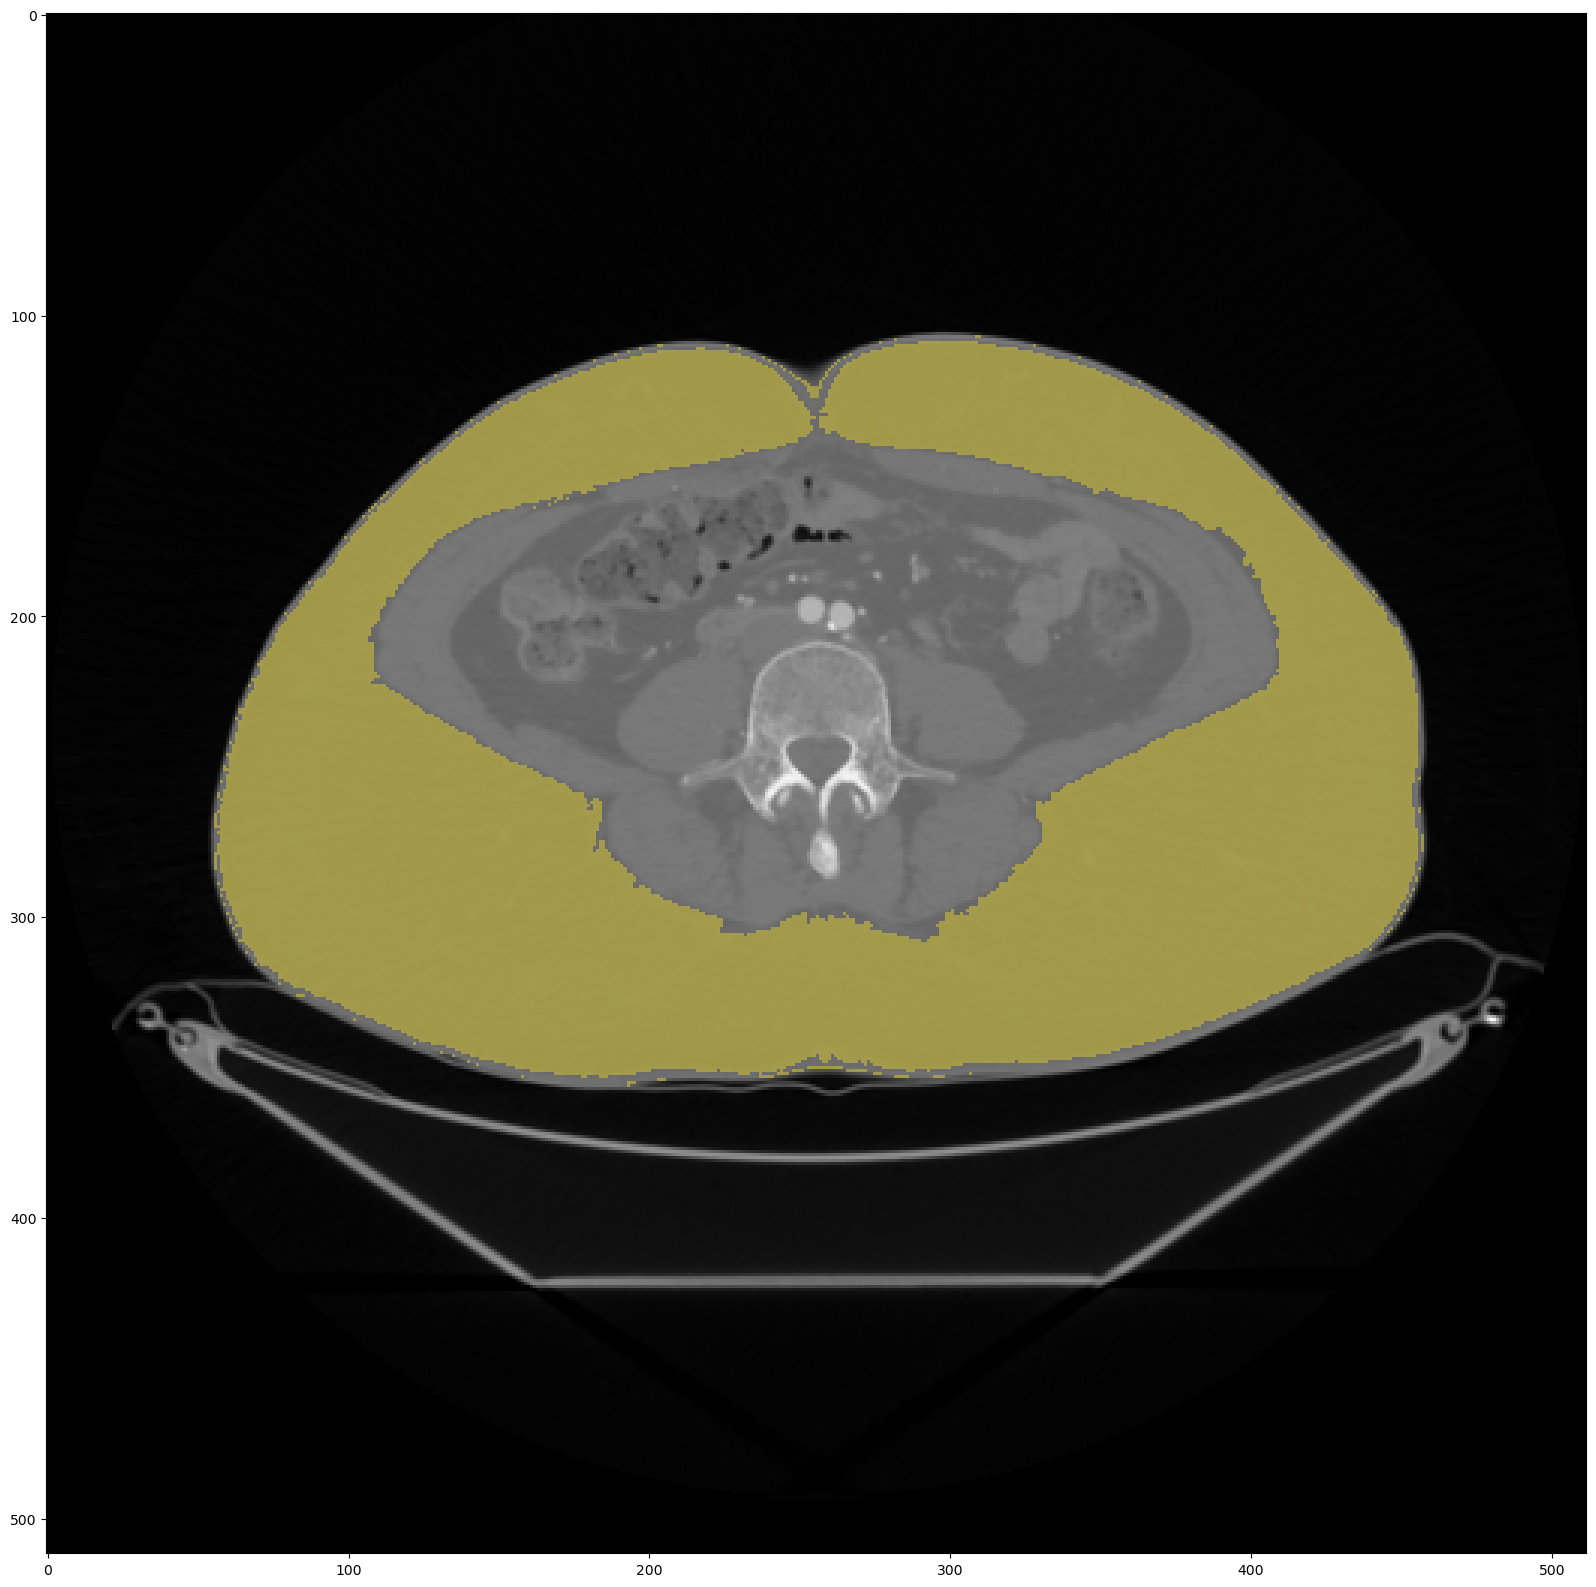

In [180]:
def segment_fat(sitk_image, seed):
    fat_and_around = get_region_grown(sitk_image, seed, 15, 3)
    temp = sitk.GetArrayFromImage(sitk_image)
    fat_and_organs = (temp > a_b_range[0]) & (temp < a_b_range[1])
    fat = fat_and_organs * fat_and_around
    
    fat = [fill_small_holes(s, 100) for s in fat]
    fat = np.array(fat)
    
    return fat


sitk_image = sitk.ReadImage(nifti_dir)
plt.figure(figsize=(20, 20))
plt.imshow(sitk.GetArrayFromImage(sitk_image)[seed[0]], cmap='gray')
fat_seg2 = segment_fat(sitk_image, seed)
plt.imshow(fat_seg2[seed[0]], alpha=fat_seg2[seed[0]] * 0.4)

(-175.0, -50.0)

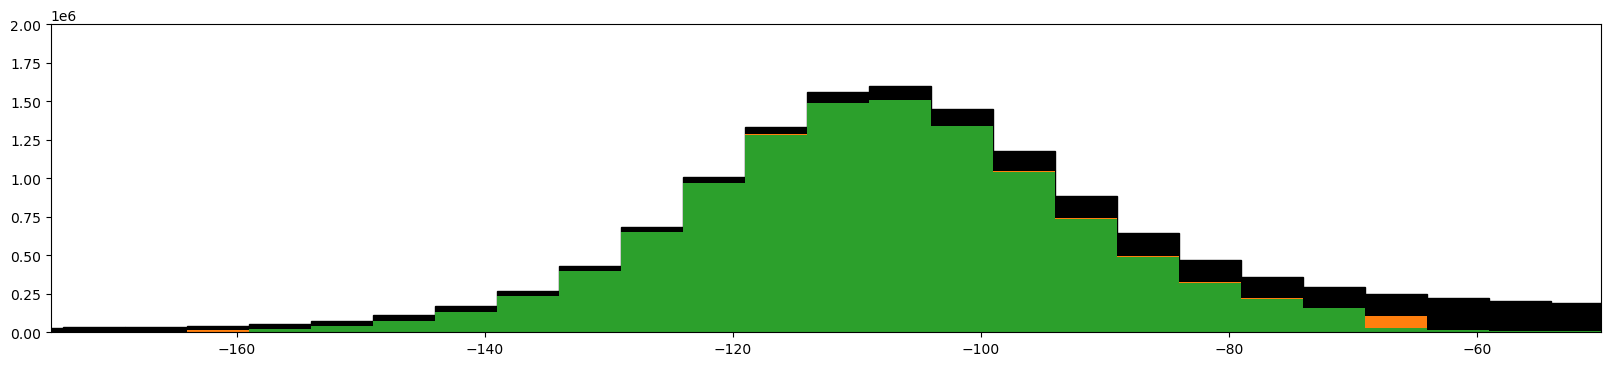

In [181]:
plt.figure(figsize=(20, 4))
temp = sitk.GetArrayFromImage(sitk_image)
plt.hist(temp.ravel(), bins=(1024 + 3071) // bin_size, range=(-1024, 3071), fc='k', ec='k')
temp2 = (temp + 100000) * fat_seg2 - 100000
plt.hist(temp2.ravel(), bins=(1024 + 3071) // bin_size, range=(-1024, 3071))
temp2 = (temp + 100000) * fat_seg - 100000
plt.hist(temp2.ravel(), bins=(1024 + 3071) // bin_size, range=(-1024, 3071))
plt.ylim(0, 2e6)
plt.xlim(-175, -50)

In [ ]:
# Convert the SimpleITK image to a NumPy array.
img = sitk.GetArrayFromImage(sitk_image)
# Clip the pixel values of the image to be within the range determined by previously calculated percentiles (a, b).
img = np.clip(img, a, b)

# Get another NumPy array from the original SimpleITK image for processing.
temp = sitk.GetArrayFromImage(sitk_image)
# Create a mask based on whether pixel values are within the specified range (a, b).
# The result is a binary array where pixels within the range are set to 1, and others to 0.
temp = ((temp >= a) & (temp <= b)).astype(float)
# Multiply the mask by the result of the region growing operation to highlight the region of interest.
# This effectively applies the mask to the segmented region, emphasizing the target area.
temp *= get_region_grown(sitk_image, seed, 25).astype(float)

# Visualize the axial slice at the seed's x-coordinate with the applied mask.
# The 'alpha' parameter controls the transparency, highlighting the region of interest.
plt.figure(figsize=(15, 15))
plt.imshow(img[seed[0], :, :], alpha=temp[seed[0], :, :])
plt.show()

# Visualize the sagittal slice, offset by 5 units from the seed's y-coordinate, with the mask.
plt.figure(figsize=(15, 15))
plt.imshow(img[:, seed[1] + 5, :], alpha=temp[:, seed[1] + 5, :])
plt.show()

# Visualize the coronal slice at the seed's z-coordinate with the mask.
plt.figure(figsize=(15, 15))
plt.imshow(img[:, :, seed[2]], alpha=temp[:, :, seed[2]])
plt.show()

In [ ]:
from skimage.filters import frangi, sato, hessian

img = sitk.GetArrayFromImage(sitk_image)
img=img[200:220]
temp=img[fat_seg2[200:220].astype(bool)]
temp, temp2= temp.min(), temp.max()
img=np.clip(img, temp, temp2)
img = (img-np.min(img))/(np.max(img)-np.min(img))
img = img*fat_seg2[200:220]


frangi_slice = frangi(img)
sato_slice = sato(img)
hessian_slice = hessian(img)

def normlize(x):
    return (x - x.min()) / (x.max() - x.min())


vesselness_slice = (normlize(frangi_slice)*0 +
                    normlize(sato_slice) +
                    normlize(hessian_slice)*0)



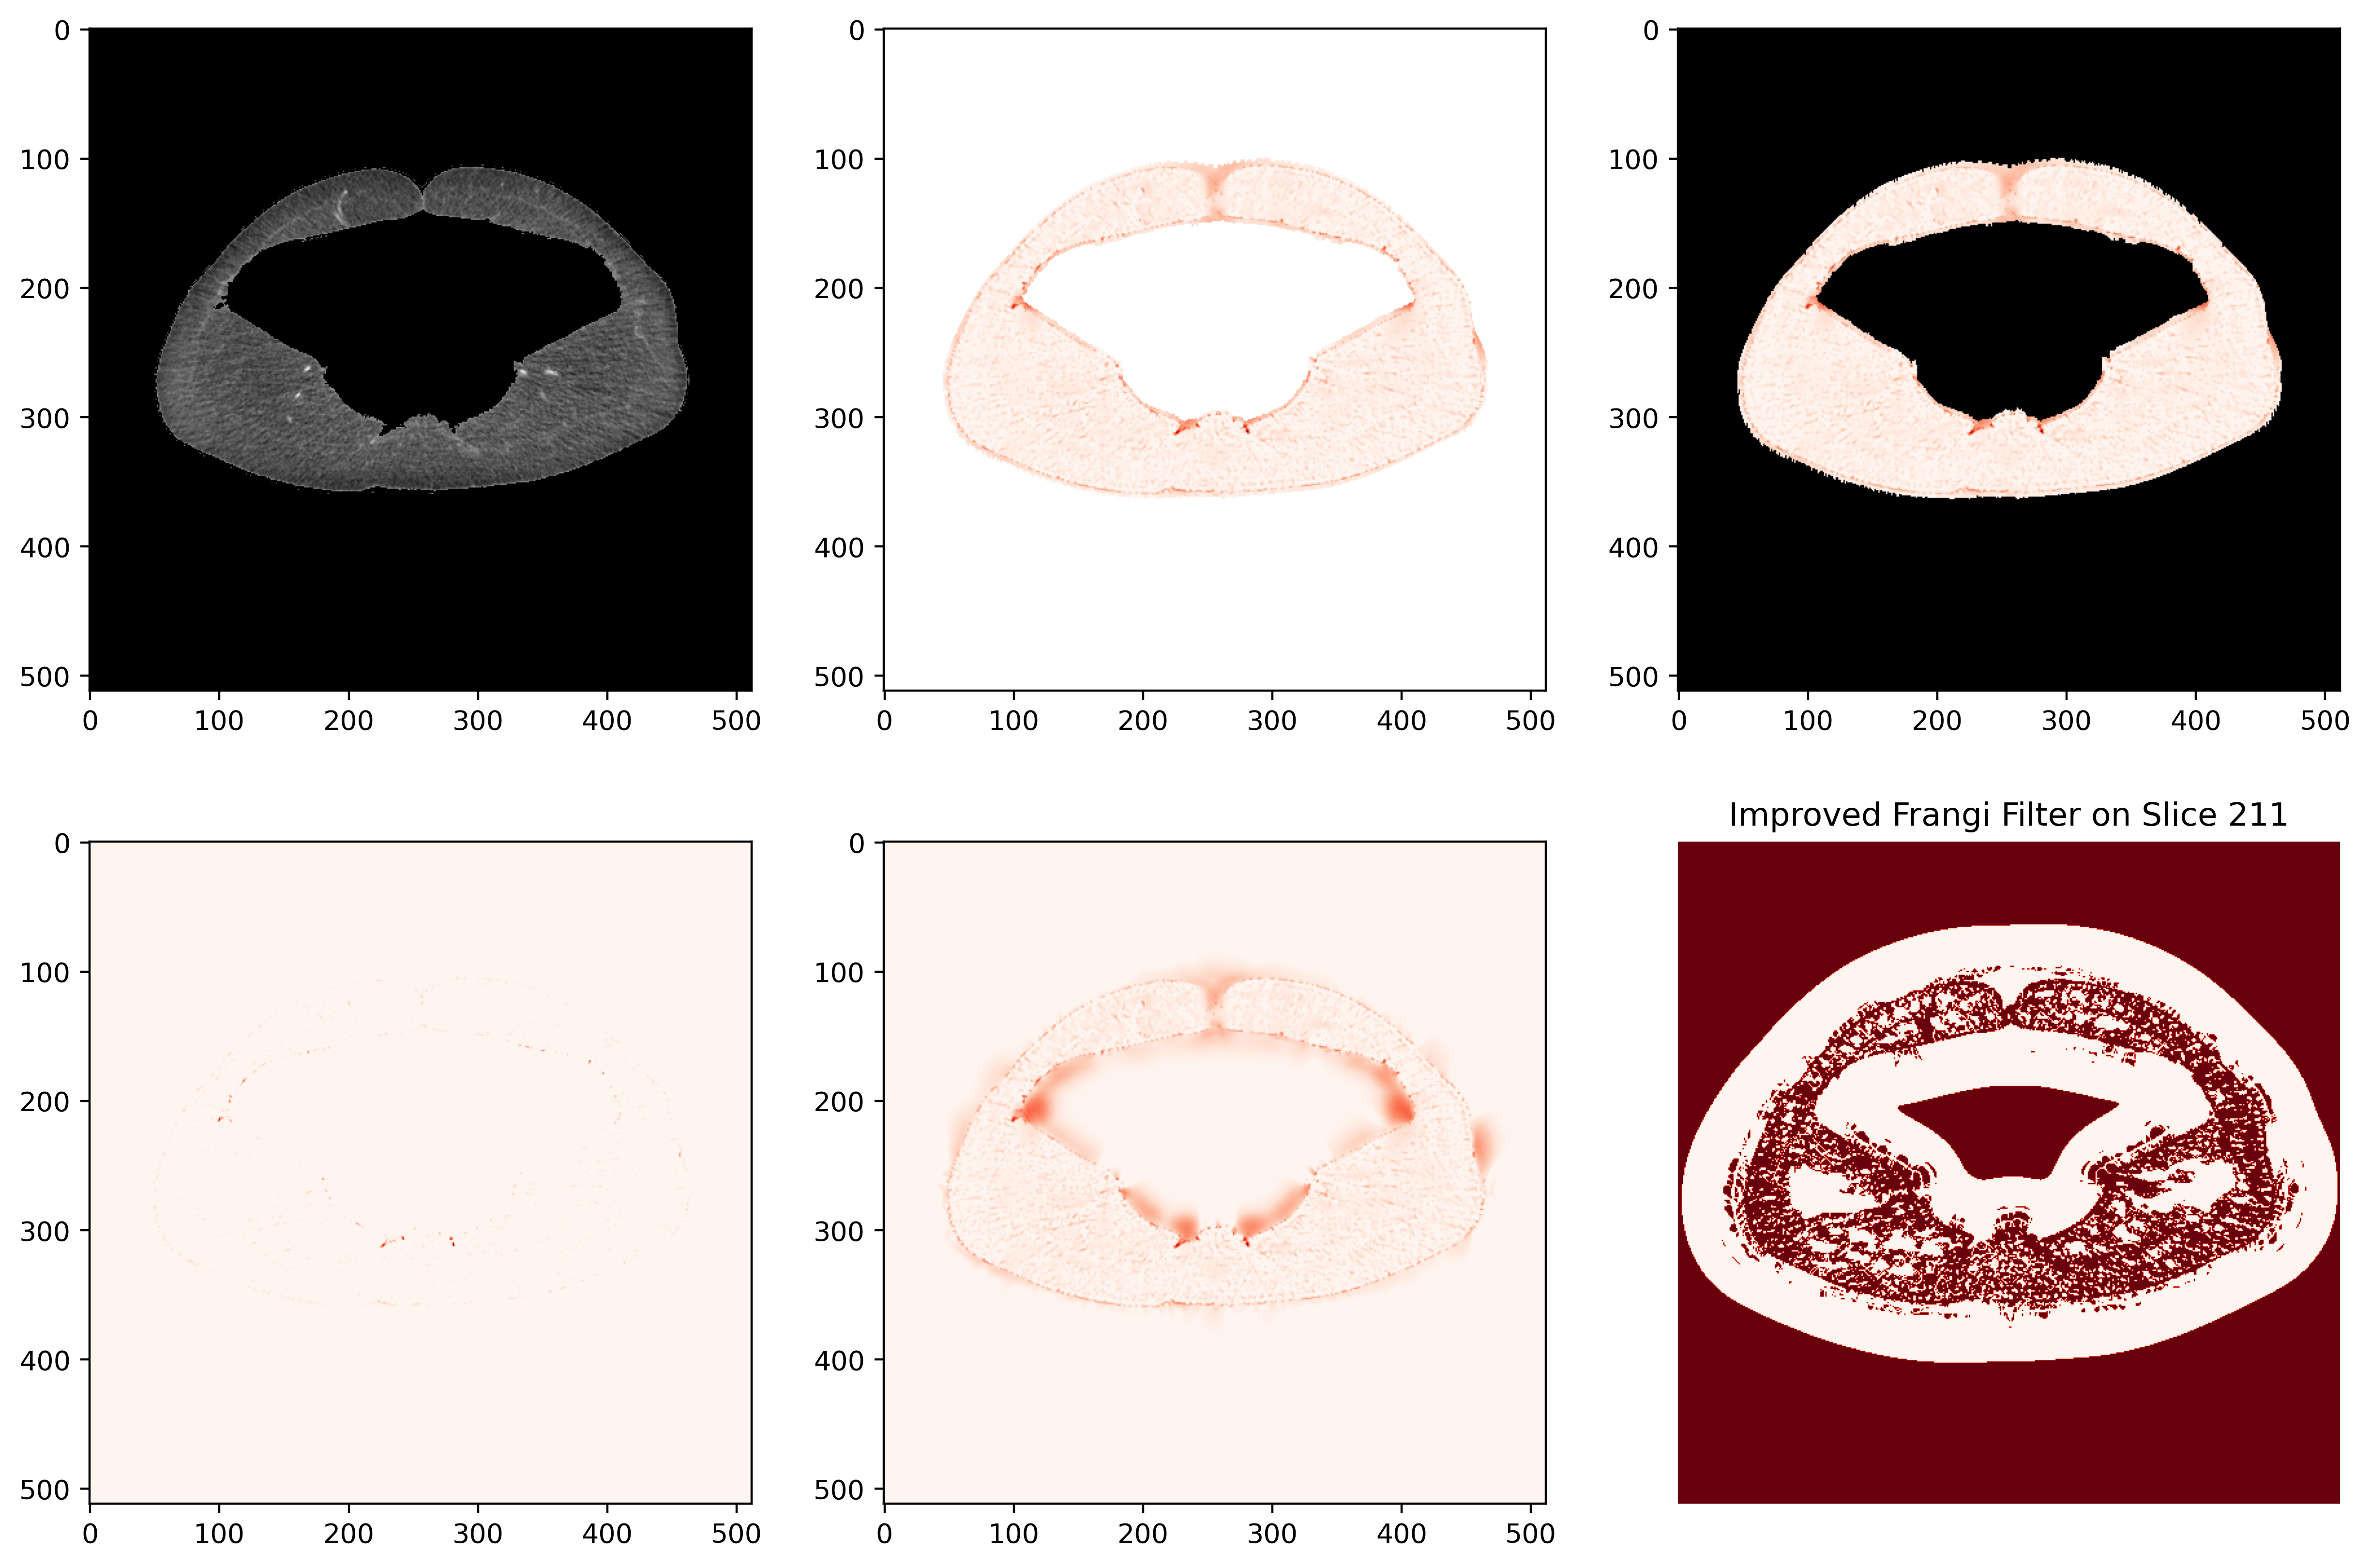

In [186]:

fig, ax = plt.subplots(2, 3, figsize=(15, 10),dpi=400)
ax[0,0].imshow(img[11], cmap='gray')
ax[0,0].imshow(img[11]*0, cmap='gray', alpha=(1-fat_seg2[200:220][11])*0.5)

temp=cv2.dilate(fat_seg2[200:220], np.ones((3,3)), iterations=3).astype(float)[11]
# ax[0,1].imshow(vesselness_slice[11], cmap='Reds', alpha=temp * 0.1)
ax[0,1].imshow(vesselness_slice[11], cmap='Reds', alpha=temp)


ax[0,2].imshow(img[11], cmap='gray')
ax[0,2].imshow(vesselness_slice[11], cmap='Reds', alpha=temp)

ax[1,0].imshow(frangi_slice[11], cmap='Reds')
ax[1,1].imshow(sato_slice[11], cmap='Reds')
ax[1,2].imshow(hessian_slice[11], cmap='Reds')

plt.title(f'Improved Frangi Filter on Slice {200 + 11}')
plt.axis('off')
plt.show()

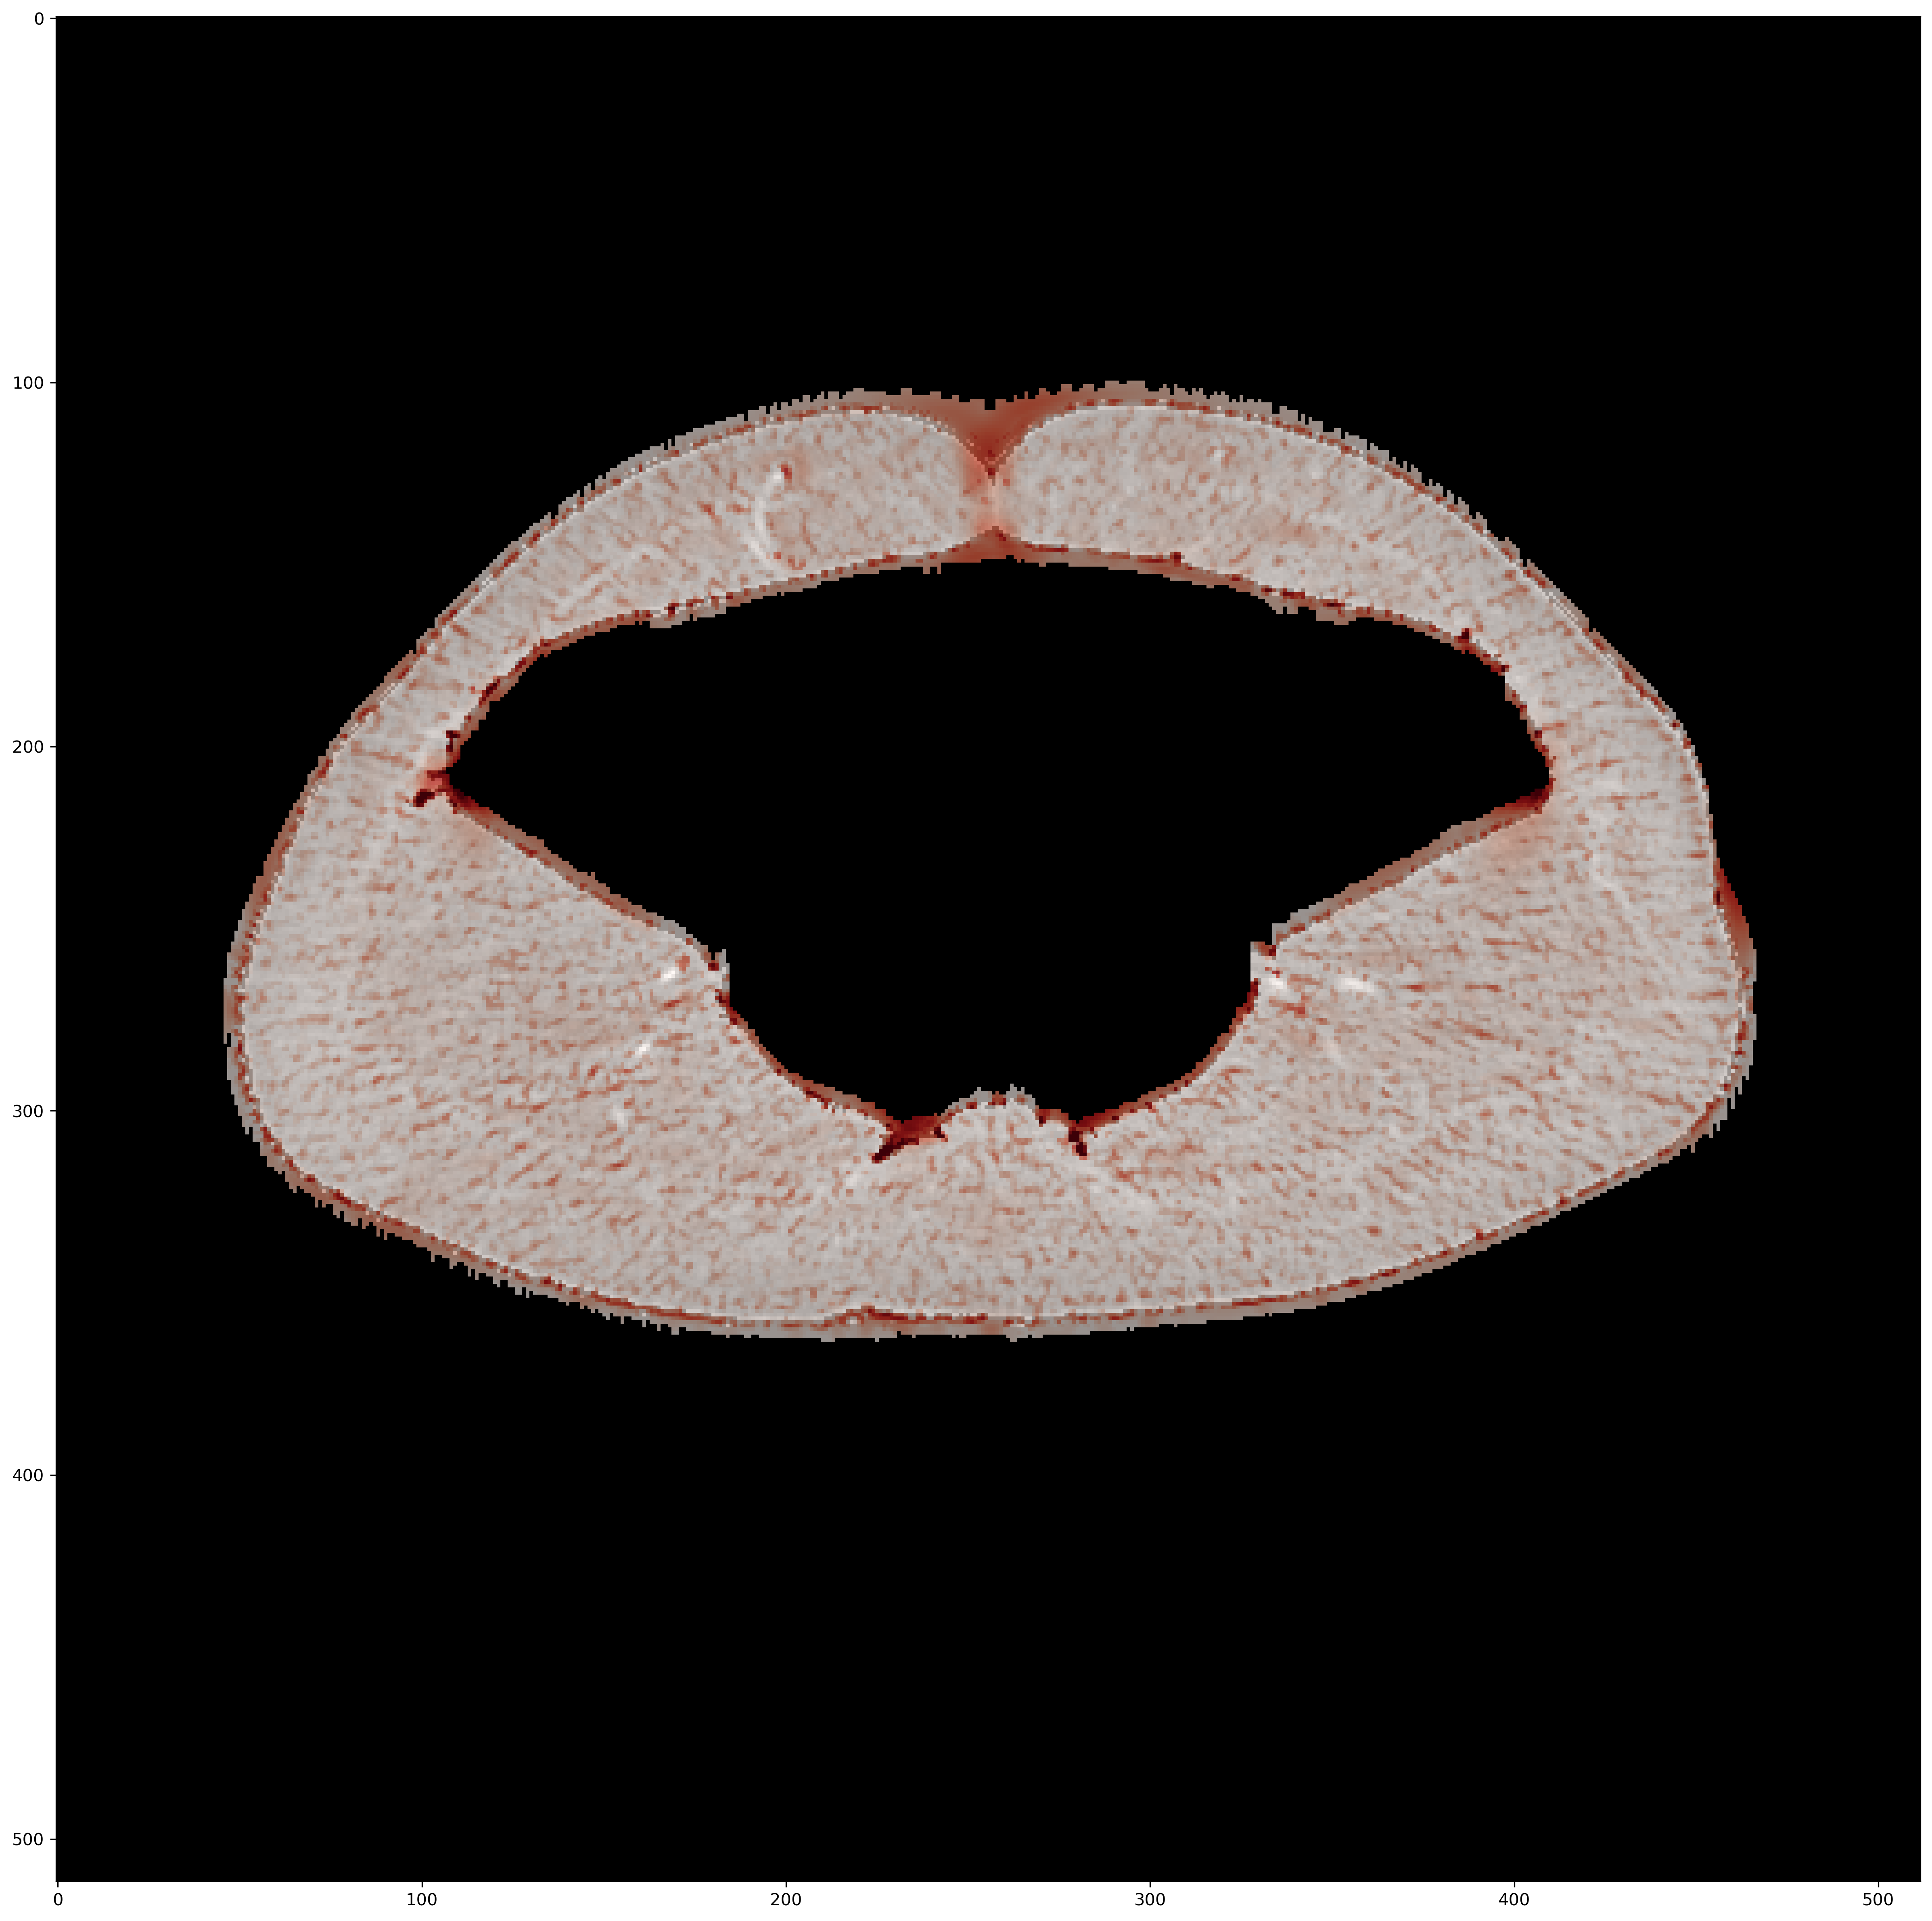

In [187]:
plt.figure(figsize=(20, 20), dpi=300)
plt.imshow(img[11], cmap='gray')
plt.imshow(np.clip(vesselness_slice[11],0,.5), cmap='Reds', alpha=temp*.6)
plt.show()

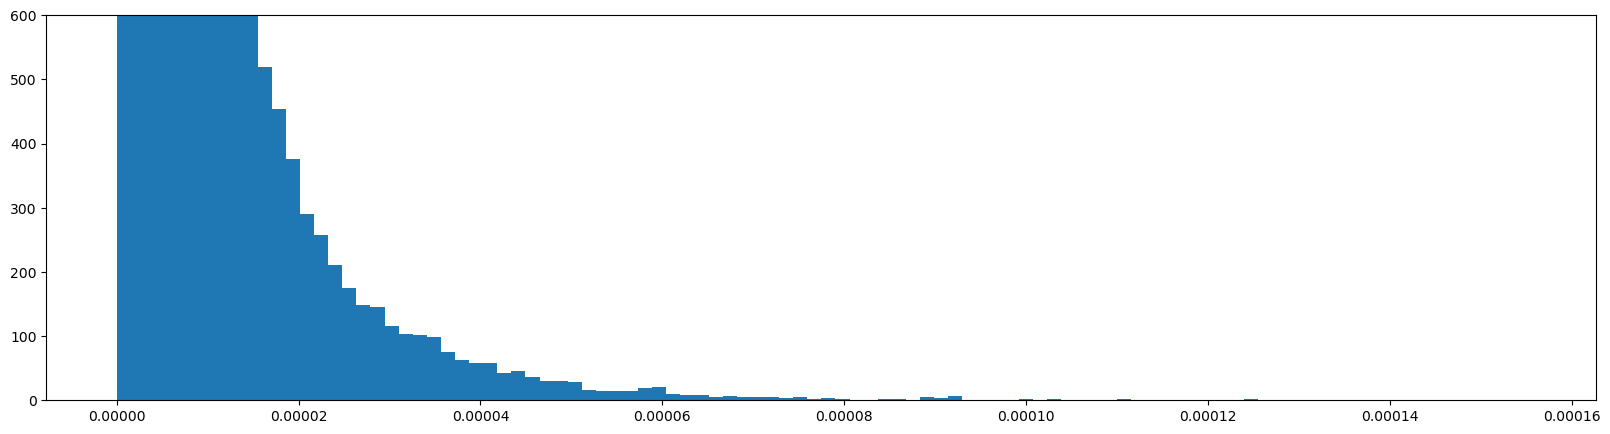

In [91]:
plt.figure(figsize=(20, 5))
plt.hist(vesselness_slice.ravel(), bins=100)
plt.ylim(0, 0.06e4)
plt.show()

In [ ]:
def preprocess_for_intensity_range(image_slice, lower_bound, upper_bound):
    """
    Preprocess an image slice to mask out intensities outside a specific range.

    Parameters:
    - image_slice: The image slice to process.
    - lower_bound: The lower bound of the desired intensity range.
    - upper_bound: The upper bound of the desired intensity range.

    Returns:
    - A preprocessed image slice with intensities outside the desired range set to the mean intensity of the range.
    """
    # Create a mask for pixels within the desired intensity range
    mask = (image_slice >= lower_bound) & (image_slice <= upper_bound)

    # Optional: Set values outside the range to the mean intensity of the range
    # This step is optional and can be adjusted based on your specific needs
    image_slice[~mask] = (lower_bound + upper_bound) / 2

    return image_slice


# Define the intensity range of interest for vessels
lower_bound = -40  # Adjust based on your observations
upper_bound = 70  # Adjust based on your observations

# Apply preprocessing and the Frangi filter to each slice
for i in range(start_slice, end_slice + 1):
    # Preprocess the slice to focus on the specific intensity range
    preprocessed_slice = preprocess_for_intensity_range(img[i, :, :], lower_bound, upper_bound)

    # Apply the Frangi filter
    vesselness_slice = frangi(preprocessed_slice, sigmas=range(1, 10, 2), alpha=0.5, beta=0.5, gamma=15)

    plt.figure(figsize=(8, 8))
    plt.imshow(img[i, :, :], cmap='gray')  # Display the original slice for reference
    plt.imshow(vesselness_slice, cmap='Reds', alpha=0.5)  # Overlay the Frangi filter output
    plt.title(f'Frangi Filter on Slice {i} with Intensity Preprocessing')
    plt.axis('off')
    plt.show()